# 02 · Demand surface with uncertainty

**Question.** How much public charging energy will each hex need, today and in 2030, and how sure are we?

**Method.** Structural bottom-up model (`chargescape.models.structural_demand`): EV stock × annual km × kWh/km × public-charging share (depends on off-street parking) with triangular priors and 500 Monte Carlo draws → P10/P50/P90 per hex. Destination/en-route demand is redistributed to activity cells by an attraction mix (vehicle-km, dwell POIs, rail, parking); a separate taxi & private-hire component follows LAEI taxi+PHV vehicle-km. 2030 scenarios use UKPN DFES 2026 pathways. Status of the result: **synthetic (model) on observed inputs** — and checked against observed aggregates below.

In [1]:
import warnings, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from chargescape.utils.paths import PROCESSED, INTERIM, FIGURES, TABLES, DOCS
from chargescape.utils.io import read_gdf
from chargescape.viz.figures import hex_map, save, barh, boroughs
from chargescape.utils.reference import dft_la, charging_sites
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
feats = read_gdf(PROCESSED / "hex_features_r8.small.parquet")
print(feats.shape)

(2374, 81)


In [2]:
from chargescape.models.structural_demand import DemandPriors
from chargescape.models.demand_pipeline import AttractionWeights, PHVPriors, COMPANY_FACTOR
pri = DemandPriors(); print("priors:", {k: v for k, v in pri.__dict__.items() if k not in ("extra",)})
print("attraction mix:", AttractionWeights().__dict__); print("PHV priors:", PHVPriors().__dict__); print("company-kept EV factor:", COMPANY_FACTOR)
dem = pd.read_parquet(PROCESSED / "demand_r8.small.parquet")
tot = dem.groupby("scenario")[[c for c in dem.columns if c.endswith(("_p10", "_p50", "_p90"))]].sum() / 1e6
tot.round(1)

priors: {'annual_km': (9000, 11500, 14000), 'kwh_per_km': (0.16, 0.19, 0.24), 'public_share_home_access': (0.05, 0.12, 0.25), 'public_share_no_home': (0.55, 0.75, 0.95), 'rapid_share_of_public': (0.25, 0.4, 0.6), 'phev_factor': (0.25, 0.4, 0.55), 'seed': 42, 'n_draws': 500}
attraction mix: {'vkm_total': 0.45, 'poi_dwell': 0.35, 'rail': 0.1, 'parking': 0.1}
PHV priors: {'phv_ev_2026': (14000, 20000, 26000), 'annual_km': (35000, 45000, 55000), 'kwh_per_km': (0.17, 0.2, 0.24), 'public_share': (0.7, 0.85, 0.95), 'growth_2030': (2.0, 3.0, 4.5)}
company-kept EV factor: 0.5


,res_kwh_p10,res_kwh_p50,res_kwh_p90,dest_kwh_p10,dest_kwh_p50,dest_kwh_p90,total_kwh_p10,total_kwh_p50,total_kwh_p90,phv_kwh_p10,phv_kwh_p50,phv_kwh_p90
scenario,,,,,,,,,,,,
2026,58.2,78.4,101.1,39.5,54.8,72.6,215.8,284.9,361.5,118.1,151.7,187.8
2030_high,408.6,550.2,711.1,278.4,384.0,507.4,1020.9,1406.6,1843.3,333.9,472.4,624.8
2030_low,276.1,372.0,480.1,187.1,259.5,344.3,797.1,1104.0,1449.2,333.9,472.4,624.8
2030_mid,383.8,516.8,668.0,261.5,360.6,476.4,979.2,1349.9,1769.3,333.9,472.4,624.8


## 1. Where the demand is (2026, P50) and how uncertain it is

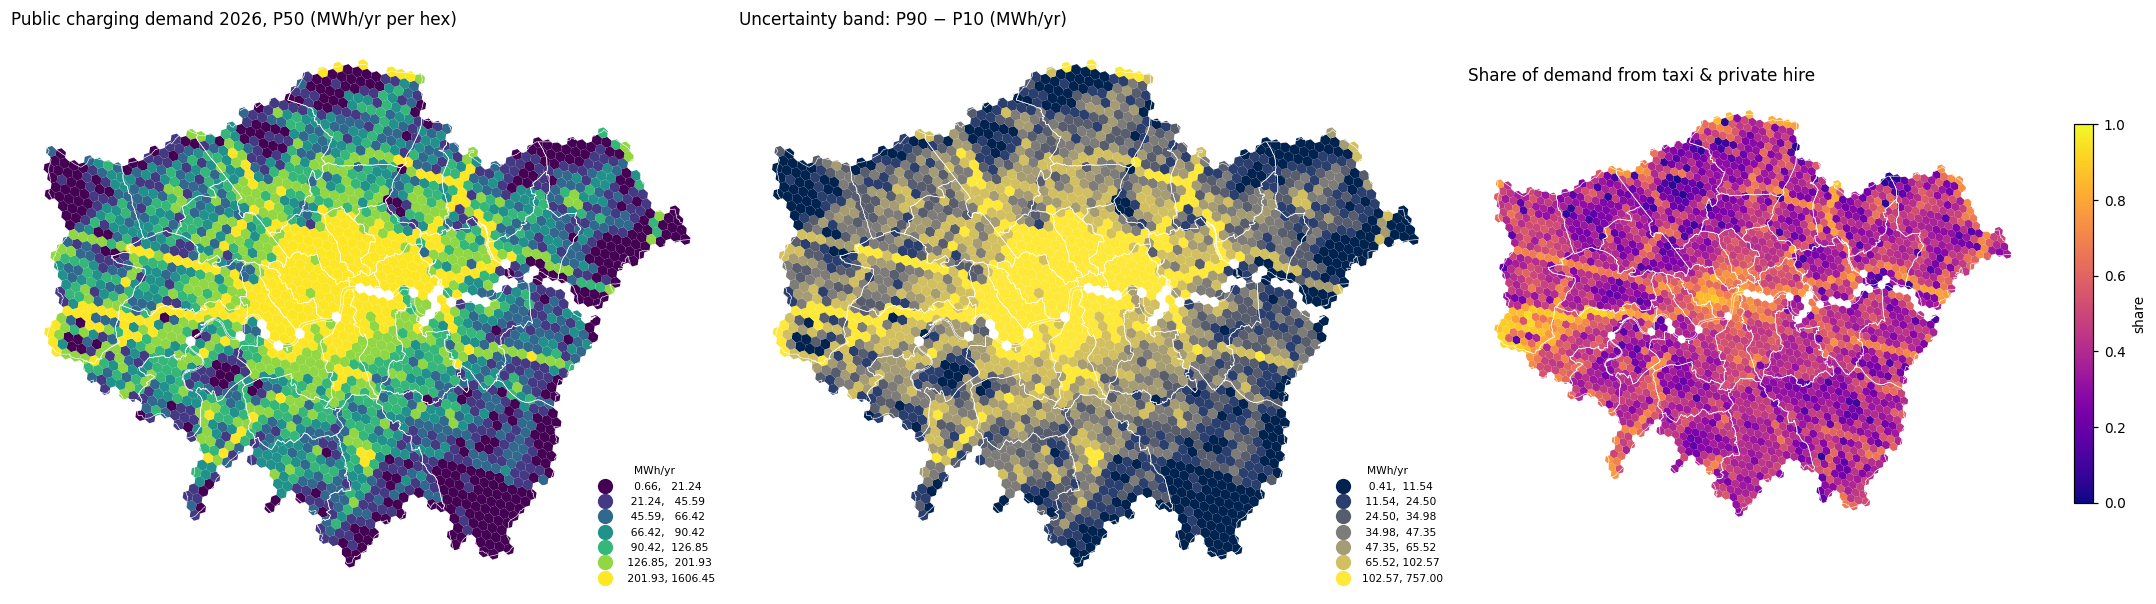

In [3]:
d26 = dem[dem.scenario == "2026"].set_index("h3")
g = feats.set_index("h3").join(d26, how="left").reset_index()
g["total_mwh_p50"] = g["total_kwh_p50"] / 1e3
g["uncert_band_mwh"] = (g["total_kwh_p90"] - g["total_kwh_p10"]) / 1e3
g["phv_share"] = g["phv_kwh_p50"] / g["total_kwh_p50"].replace(0, np.nan)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
hex_map(g, "total_mwh_p50", "Public charging demand 2026, P50 (MWh/yr per hex)", cmap="viridis", scheme="quantiles", k=7, ax=axes[0], legend_label="MWh/yr")
hex_map(g, "uncert_band_mwh", "Uncertainty band: P90 − P10 (MWh/yr)", cmap="cividis", scheme="quantiles", k=7, ax=axes[1], legend_label="MWh/yr")
hex_map(g, "phv_share", "Share of demand from taxi & private hire", cmap="plasma", vmin=0, vmax=1, ax=axes[2], legend_label="share")
plt.tight_layout(); save(fig, "02_demand_p50_uncertainty.png"); plt.show()

## 2. Sanity checks against observed aggregates

The model was not fitted to London usage data (none is open), so we check its total against quantities that *are* observed:
1. the supply side — DfT counts of chargers × TfL-reported occupancy by charger type (slow chargers occupied 46–49 % of the time, ultra-rapid ~34 %, March 2025);
2. per-charger throughput in Dundee's open session log (median 16 kWh per rapid session, ~3 sessions per charger per day in a small city).

In [4]:
dft = dft_la()
la = dft[(dft.geography == "local_authority") & (dft.date == dft.date.max())].pivot_table(index="area_name", columns="measure", values="value")
n_rapid = la["50kW+ EV chargers"].sum(); n_slow = la["EV chargers"].sum() - n_rapid
# occupancy != charging: assume charging happens during ~45% of occupied time on slow units (long dwell) and ~85% on rapid
supply_kwh = {
    "slow (7 kW, occupied 47%, charging 45% of that)": n_slow * 7 * 24 * 365 * 0.47 * 0.45,
    "rapid (avg 60 kW delivered, occupied 34%, charging 85% of that)": n_rapid * 60 * 24 * 365 * 0.34 * 0.85,
}
imp = pd.Series(supply_kwh) / 1e6
print(f"DfT chargers: {n_slow:,.0f} slow, {n_rapid:,.0f} rapid")
print("Supply-implied energy, GWh/yr:\n", imp.round(0), "\n total ≈", round(imp.sum()), "GWh/yr")
m = tot.loc["2026"]
print(f"\nModel 2026: near-home {m['res_kwh_p50']:.0f} GWh (P10–P90 {m['res_kwh_p10']:.0f}–{m['res_kwh_p90']:.0f}); rapid-type (destination+PHV) {m['dest_kwh_p50']+m['phv_kwh_p50']:.0f} GWh; total {m['total_kwh_p50']:.0f} GWh (P10–P90 {m['total_kwh_p10']:.0f}–{m['total_kwh_p90']:.0f})")
rapid_sessions_day = (m['dest_kwh_p50'] + m['phv_kwh_p50']) * 1e6 / 17 / 365
print(f"→ implied rapid sessions per charger per day: {rapid_sessions_day / n_rapid:.1f}  (TfL occupancy 34% with 38-min sessions ⇒ ~{0.34*24*60/38:.0f}/day; Dundee observed ≈3/day)")

DfT chargers: 28,838 slow, 2,533 rapid
Supply-implied energy, GWh/yr:
 slow (7 kW, occupied 47%, charging 45% of that)                    374.0
rapid (avg 60 kW delivered, occupied 34%, charging 85% of that)    385.0
dtype: float64 
 total ≈ 759 GWh/yr

Model 2026: near-home 78 GWh (P10–P90 58–101); rapid-type (destination+PHV) 207 GWh; total 285 GWh (P10–P90 216–361)
→ implied rapid sessions per charger per day: 13.1  (TfL occupancy 34% with 38-min sessions ⇒ ~13/day; Dundee observed ≈3/day)


**A note on the uncertainty map.** The P90−P10 band scales with the level of demand because the priors are global; the *relative* band is nearly constant (P90/P10 ≈ 1.7) and only shifts with the local mix of near-home, destination and PHV demand. Spatially varying uncertainty would need local calibration data — which is precisely what the post-hoc validation plan collects.

**Reading.** The model's rapid-type demand lands at the order of magnitude implied by TfL's observed occupancy of London's rapid network, while the near-home component sits below the energy that 28k slow chargers *could* be delivering — consistent with the known low charging-time share of long-dwell on-street sessions. The wide P10–P90 band is the honest statement: the biggest levers are the public-charging share of drivers without a driveway and the size of the electric PHV fleet.

## 3. 2030 scenarios (UKPN DFES 2026 pathways) — where growth concentrates

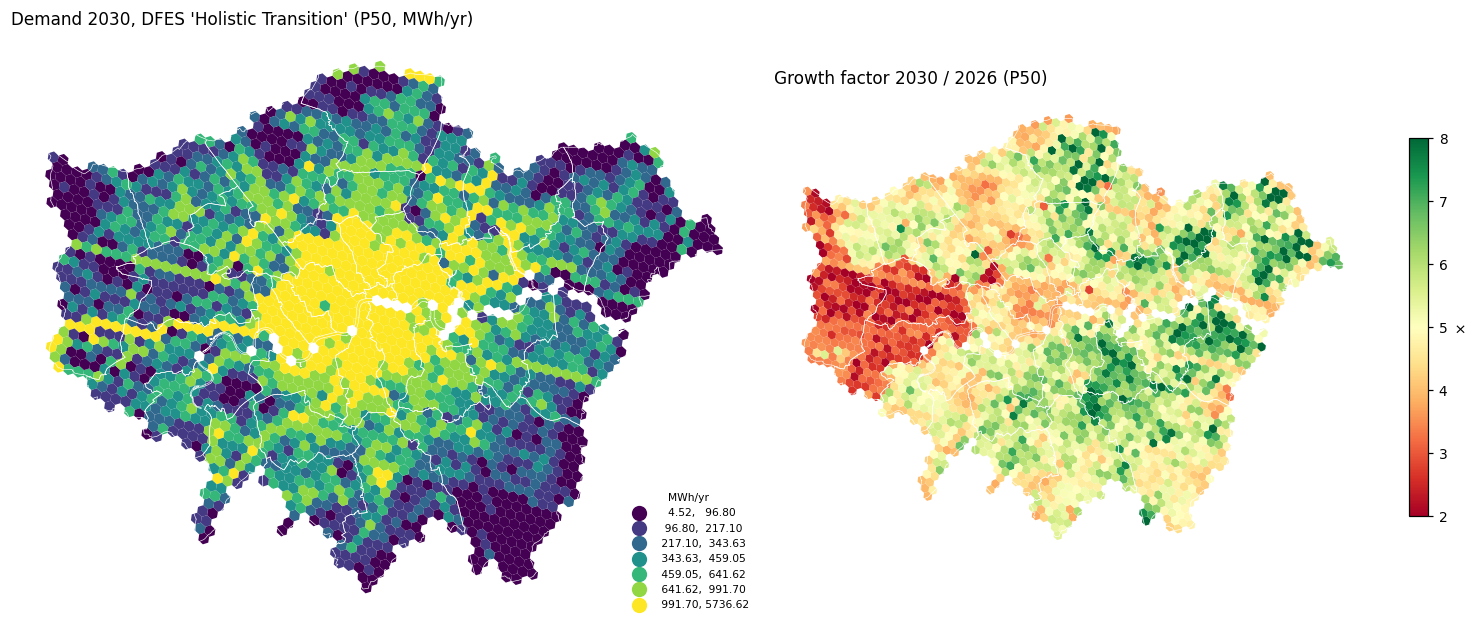

           total_kwh_p10  total_kwh_p50  total_kwh_p90
scenario                                              
2026               216.0          285.0          361.0
2030_high         1021.0         1407.0         1843.0
2030_low           797.0         1104.0         1449.0
2030_mid           979.0         1350.0         1769.0


,GWh_2026,GWh_2030_mid
borough,,
Westminster,23.9,95.9
Hillingdon,17.1,58.8
Lambeth,10.6,56.4
Southwark,10.5,56.0
Camden,11.8,55.2
Barnet,11.9,53.8
Hounslow,15.8,48.7
Enfield,8.9,48.0
Tower Hamlets,10.8,47.0


In [5]:
d30 = dem[dem.scenario == "2030_mid"].set_index("h3")
g["growth_2030_mid"] = g["h3"].map(d30["total_kwh_p50"]) / g["total_kwh_p50"].replace(0, np.nan)
g["total_2030_mid_mwh"] = g["h3"].map(d30["total_kwh_p50"]) / 1e3
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
hex_map(g, "total_2030_mid_mwh", "Demand 2030, DFES 'Holistic Transition' (P50, MWh/yr)", cmap="viridis", scheme="quantiles", k=7, ax=axes[0], legend_label="MWh/yr")
hex_map(g, "growth_2030_mid", "Growth factor 2030 / 2026 (P50)", cmap="RdYlGn", vmin=2, vmax=8, ax=axes[1], legend_label="×")
plt.tight_layout(); save(fig, "02_demand_2030.png"); plt.show()
print(tot[["total_kwh_p10", "total_kwh_p50", "total_kwh_p90"]].round(0))
bor = g.groupby("borough")[["total_kwh_p50"]].sum().join(g.groupby("borough")["total_2030_mid_mwh"].sum() * 1e3)
(bor / 1e6).rename(columns={"total_kwh_p50": "GWh_2026", "total_2030_mid_mwh": "GWh_2030_mid"}).sort_values("GWh_2030_mid", ascending=False).round(1).head(10)